# 03 · Global explanations
What does the model do **on average**? Four views, from simple to rich:
1. Permutation importance (individual and by *groups*, because many features are correlated — see EDA).
2. SHAP (TreeSHAP) global importance and beeswarm.
3. Cross-check of the rankings (permutation vs SHAP vs logistic-regression coefficients).
4. Shape of the effects: PDP + ICE vs ALE (and SHAP dependence), the PDP/ALE gap being a red flag for correlated features.

All explanations use the LightGBM model from notebook 02. Importances are computed on held-out data (validation for permutation, a test sample for SHAP).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from src.preprocess import get_splits
from src.xai import permutation_importance_groups, ale_1d
sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
gbm = joblib.load("../models/lightgbm.joblib"); logreg = joblib.load("../models/logreg.joblib")
feats = list(X_tr.columns)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Permutation importance
Metric: drop in ROC-AUC on the **validation** set when a column is shuffled (10 repeats, mean ± std). A negative value would mean the feature only adds noise.

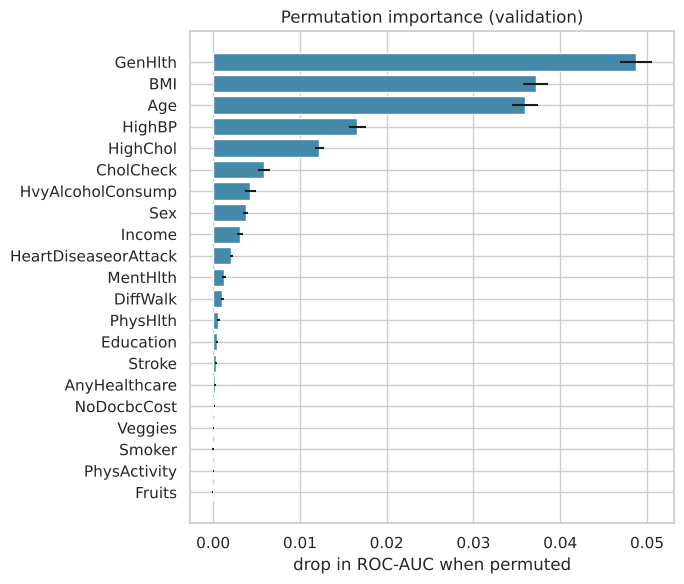

,feature,mean,std
0,GenHlth,0.0487,0.0018
1,BMI,0.0372,0.0014
2,Age,0.0359,0.0015
3,HighBP,0.0166,0.0010
4,HighChol,0.0122,0.0005
5,CholCheck,0.0059,0.0007
6,HvyAlcoholConsump,0.0043,0.0007
7,Sex,0.0037,0.0003
8,Income,0.0031,0.0004
9,HeartDiseaseorAttack,0.0021,0.0002


In [2]:
pi = permutation_importance(gbm, X_va, y_va, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
pfi = pd.DataFrame({"feature": feats, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(pfi.feature[::-1], pfi["mean"][::-1], xerr=pfi["std"][::-1], color="#48a")
ax.set_xlabel("drop in ROC-AUC when permuted"); ax.set_title("Permutation importance (validation)")
plt.tight_layout(); plt.savefig("../figures/global_perm_importance.png", dpi=150); plt.show()
pfi.round(4).head(12)

### Grouped permutation importance
Correlated features share information: shuffling one leaves its partner as a substitute, so each looks less important than the group really is.
We shuffle each **group jointly** (groups defined from domain meaning and the correlations seen in the EDA).

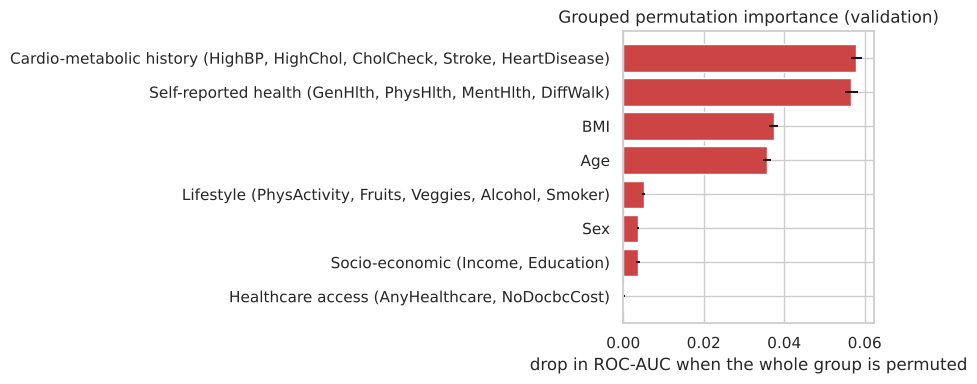

,group,n_features,mean,std
0,"Cardio-metabolic history (HighBP, HighChol, Ch...",5,0.0579,0.0014
1,"Self-reported health (GenHlth, PhysHlth, MentH...",4,0.0567,0.0017
2,BMI,1,0.0374,0.0011
3,Age,1,0.0358,0.0010
4,"Lifestyle (PhysActivity, Fruits, Veggies, Alco...",5,0.0051,0.0004
5,Sex,1,0.0037,0.0003
6,"Socio-economic (Income, Education)",2,0.0036,0.0005
7,"Healthcare access (AnyHealthcare, NoDocbcCost)",2,0.0003,0.0001


In [3]:
groups = {
 "Self-reported health (GenHlth, PhysHlth, MentHlth, DiffWalk)": ["GenHlth","PhysHlth","MentHlth","DiffWalk"],
 "Cardio-metabolic history (HighBP, HighChol, CholCheck, Stroke, HeartDisease)": ["HighBP","HighChol","CholCheck","Stroke","HeartDiseaseorAttack"],
 "Socio-economic (Income, Education)": ["Income","Education"],
 "Lifestyle (PhysActivity, Fruits, Veggies, Alcohol, Smoker)": ["PhysActivity","Fruits","Veggies","HvyAlcoholConsump","Smoker"],
 "Healthcare access (AnyHealthcare, NoDocbcCost)": ["AnyHealthcare","NoDocbcCost"],
 "BMI": ["BMI"], "Age": ["Age"], "Sex": ["Sex"],
}
gp = permutation_importance_groups(gbm, X_va, y_va, groups, n_repeats=10)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(gp.group[::-1], gp["mean"][::-1], xerr=gp["std"][::-1], color="#c44")
ax.set_xlabel("drop in ROC-AUC when the whole group is permuted"); ax.set_title("Grouped permutation importance (validation)")
plt.tight_layout(); plt.savefig("../figures/global_perm_groups.png", dpi=150, bbox_inches="tight"); plt.show()
gp.round(4)

In [4]:
# dilution check: sum of the individual importances of a group vs the joint importance
rows = []
for g, cols in groups.items():
    if len(cols) > 1:
        rows.append({"group": g.split(" (")[0], "sum of individual": pfi.set_index("feature").loc[cols, "mean"].sum(),
                     "joint": gp.set_index("group").loc[g, "mean"]})
pd.DataFrame(rows).round(4)

,group,sum of individual,joint
0,Self-reported health,0.0516,0.0567
1,Cardio-metabolic history,0.0371,0.0579
2,Socio-economic,0.0036,0.0036
3,Lifestyle,0.0044,0.0051
4,Healthcare access,0.0003,0.0003


## 2. SHAP (TreeSHAP)
Exact and fast for tree models. Values are in **log-odds** units and add up to `f(x) - E[f(X)]`. Computed on a random sample of 5,000 test rows. The reference (background) distribution is 100 random training rows (interventional SHAP); a different background changes the values somewhat.

In [5]:
rng = np.random.default_rng(0)
Xs = X_te.iloc[rng.choice(len(X_te), 5000, replace=False)]
expl = shap.TreeExplainer(gbm, data=X_tr.sample(100, random_state=0), feature_perturbation="interventional", model_output="raw")
sv = expl(Xs)
print("shap values shape:", sv.values.shape, "| base value (mean log-odds):", np.round(sv.base_values.mean(), 3))
# additivity check
raw = gbm.predict(Xs, raw_score=True)
print("max |sum(shap)+base - raw prediction|:", float(np.abs(sv.values.sum(1) + sv.base_values - raw).max()))

 20%|====                | 1022/5000 [00:11<00:42]       

 22%|====                | 1117/5000 [00:12<00:41]       

 24%|=====               | 1208/5000 [00:13<00:40]       

 26%|=====               | 1302/5000 [00:14<00:39]       

 28%|======              | 1399/5000 [00:15<00:38]       

...

 94%|=================== | 4697/5000 [00:51<00:03]       

 96%|=================== | 4786/5000 [00:52<00:02]       

 98%|===================| 4876/5000 [00:53<00:01]       

 99%|===================| 4964/5000 [00:54<00:00]       

shap values shape: (5000, 21) | base value (mean log-odds): -2.148
max |sum(shap)+base - raw prediction|: 1.5841939982053077e-07


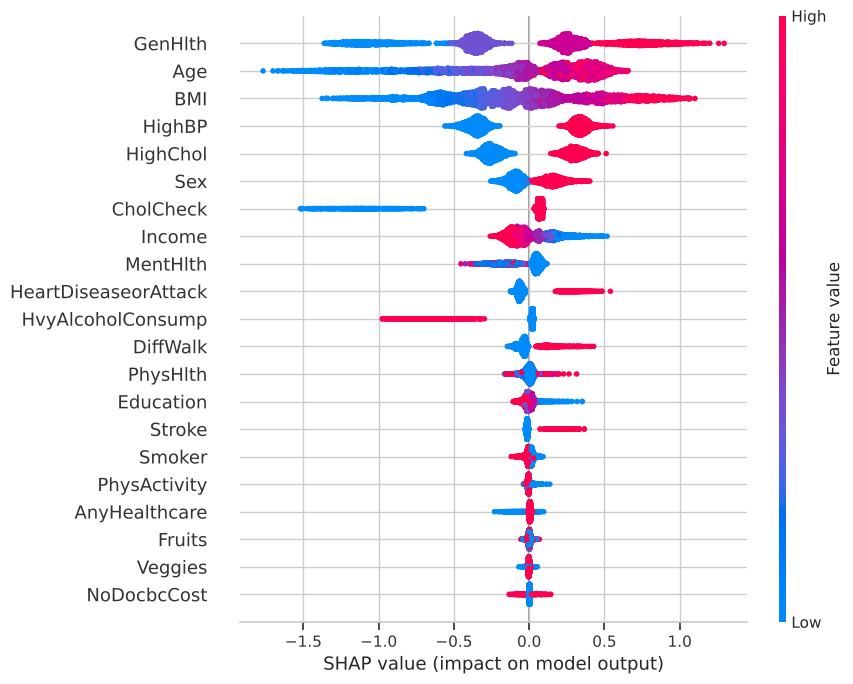

In [6]:
plt.figure(); shap.plots.beeswarm(sv, max_display=21, show=False)
plt.gcf().set_size_inches(9, 7); plt.tight_layout(); plt.savefig("../figures/global_shap_beeswarm.png", dpi=150); plt.show()

In [7]:
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=feats).sort_values(ascending=False)
shap_imp.round(3).head(12)

GenHlth                 0.503
Age                     0.389
BMI                     0.379
HighBP                  0.349
HighChol                0.274
Sex                     0.123
CholCheck               0.119
Income                  0.109
MentHlth                0.093
HeartDiseaseorAttack    0.084
HvyAlcoholConsump       0.066
DiffWalk                0.062
dtype: float64

## 3. Do the methods agree?
Three global rankings: permutation importance (error-based), mean |SHAP| (attribution-based), and standardised logistic-regression coefficients (the transparent baseline).

In [8]:
coef = pd.Series(np.abs(logreg[-1].coef_[0]), index=feats)   # features were standardised in the pipeline
cmp = pd.DataFrame({"permutation": pfi.set_index("feature")["mean"], "mean|SHAP|": shap_imp, "|coef| logreg": coef}).loc[feats]
rk = cmp.rank(ascending=False)
print(rk.corr(method="spearman").round(2))
rk.sort_values("mean|SHAP|").astype(int)

               permutation  mean|SHAP|  |coef| logreg
permutation           1.00        0.95           0.96
mean|SHAP|            0.95        1.00           0.96
|coef| logreg         0.96        0.96           1.00


,permutation,mean|SHAP|,|coef| logreg
GenHlth,1,1,1
Age,3,2,3
BMI,2,3,2
HighBP,4,4,4
HighChol,5,5,5
Sex,8,6,8
CholCheck,6,7,6
Income,9,8,9
MentHlth,11,9,13
HeartDiseaseorAttack,10,10,10


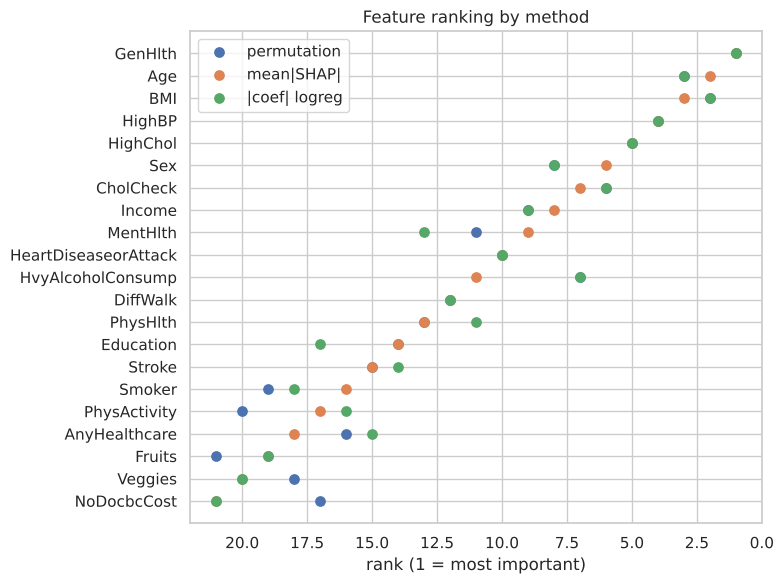

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
order = rk.sort_values("mean|SHAP|").index
for j, c in enumerate(["permutation","mean|SHAP|","|coef| logreg"]):
    ax.scatter(rk.loc[order, c], range(len(order)), label=c, s=45)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis(); ax.invert_xaxis()
ax.set_xlabel("rank (1 = most important)"); ax.legend(); ax.set_title("Feature ranking by method")
plt.tight_layout(); plt.savefig("../figures/global_rank_comparison.png", dpi=150); plt.show()

## 4. Shape of the effects: ICE / PDP vs ALE
Computed in log-odds on a 1,000-row sample of validation. **ICE** (grey) = one curve per person, **PDP** (red) = their mean, **ALE** (blue, centred) uses only realistic neighbours (both curves are re-centred at the middle of the grid, so only their *shape* should be compared, not their absolute level). ALE bins are quantile-based, so for ordinal features with few levels (e.g. `GenHlth`) the last level may not get its own bin.
If PDP and ALE disagree and the feature is correlated with others, the PDP is extrapolating to unrealistic combinations.

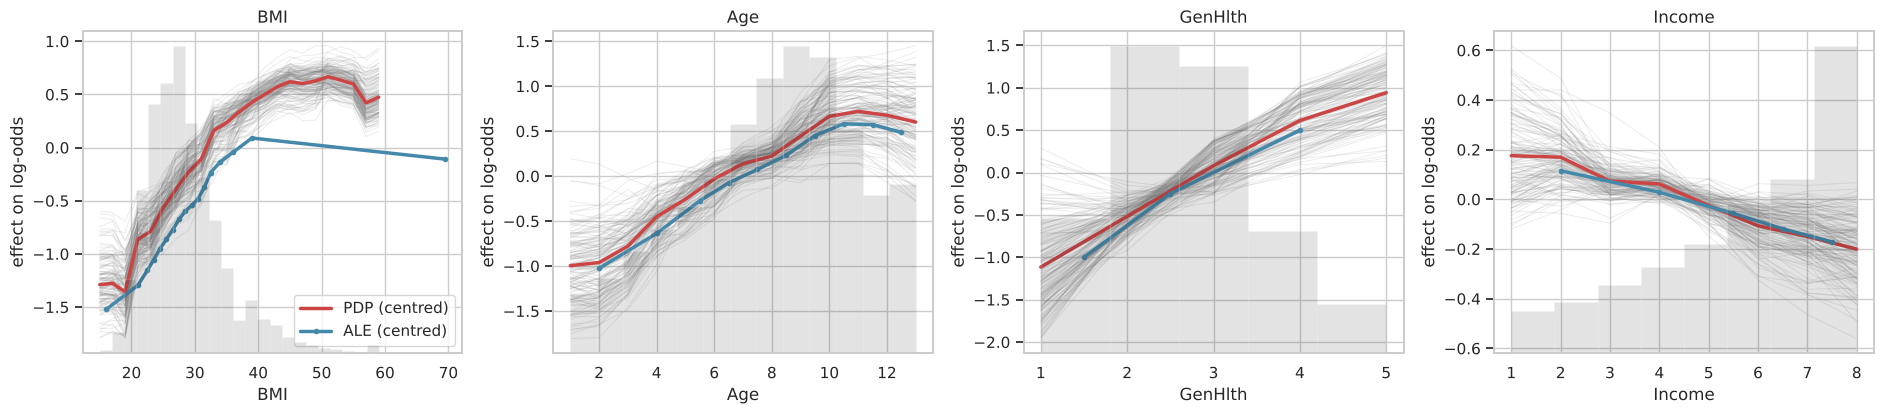

In [10]:
def logit(m, Z):
    p = np.clip(m.predict_proba(Z)[:,1], 1e-6, 1-1e-6); return np.log(p/(1-p))

def ice_pdp(model, X, feature, grid):
    curves = []
    for v in grid:
        Z = X.copy(); Z[feature] = v; curves.append(logit(model, Z))
    return np.array(curves).T            # (n_samples, n_grid)

Xv = X_va.sample(1000, random_state=0)
feature_grids = {"BMI": np.arange(15, 61, 2), "Age": np.arange(1, 14), "GenHlth": np.arange(1, 6), "Income": np.arange(1, 9)}
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (f, grid) in zip(axes, feature_grids.items()):
    ice = ice_pdp(gbm, Xv, f, grid)
    ice_c = ice - ice.mean(1, keepdims=True)                     # centred ICE: shows slope differences
    for row in ice_c[:150]: ax.plot(grid, row, c="grey", alpha=.15, lw=.7)
    ax.plot(grid, ice_c.mean(0), c="#c44", lw=2.5, label="PDP (centred)")
    ed, a = ale_1d(gbm, X_va, f, n_bins=len(grid)-1 if f != "BMI" else 20)
    mids = (ed[:-1] + ed[1:]) / 2
    a_mid = (a[:-1] + a[1:]) / 2
    a_mid = a_mid - np.interp(grid.mean(), mids, a_mid)          # recentre for visual comparison
    ax.plot(mids, a_mid, c="#48a", lw=2.5, marker="o", ms=3, label="ALE (centred)")
    ax.set_title(f); ax.set_xlabel(f); ax.set_ylabel("effect on log-odds")
    ax2 = ax.twinx(); ax2.hist(X_va[f].clip(grid.min(), grid.max()), bins=len(grid), alpha=.12, color="k"); ax2.set_yticks([])
axes[0].legend()
plt.tight_layout(); plt.savefig("../figures/global_ice_pdp_ale.png", dpi=150); plt.show()

### Heterogeneity: is there interaction?
Standard deviation of the centred ICE curves (0 = every person reacts identically = no interaction) at the extremes of each feature, and the SHAP dependence plots for BMI and Age coloured by the strongest interacting feature.

In [11]:
for f, grid in feature_grids.items():
    ice = ice_pdp(gbm, Xv, f, grid); ice_c = ice - ice.mean(1, keepdims=True)
    print(f"{f:8s} spread of centred ICE (std across people, averaged over grid): {ice_c.std(0).mean():.3f}")

BMI      spread of centred ICE (std across people, averaged over grid): 0.142
Age      spread of centred ICE (std across people, averaged over grid): 0.233


GenHlth  spread of centred ICE (std across people, averaged over grid): 0.269
Income   spread of centred ICE (std across people, averaged over grid): 0.086


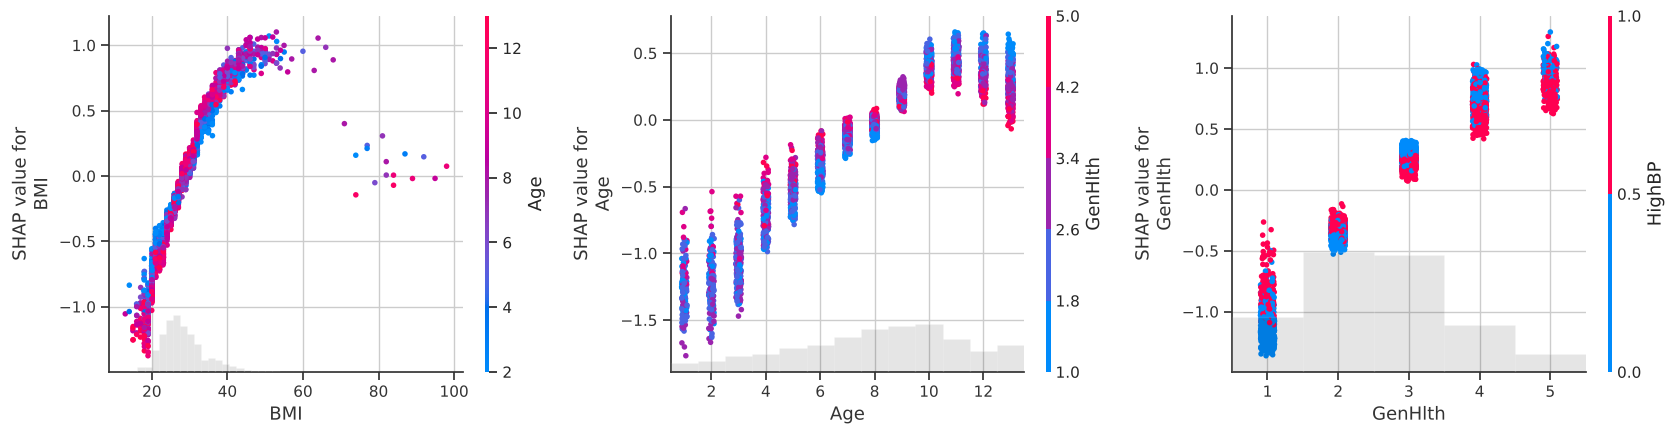

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, ["BMI", "Age", "GenHlth"]):
    shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False)
plt.tight_layout(); plt.savefig("../figures/global_shap_dependence.png", dpi=150); plt.show()